# TUẦN 4 — Phương pháp cải tiến (Proposed Method / Mô hình lai)

Pipeline hoàn chỉnh: **phát hiện can thiệp + trích xuất trường dữ liệu + đọc thông số sơ đồ**.

| Nhánh | Kỹ thuật | Đầu ra |
|---|---|---|
| A. Hình học sơ đồ | Skeletonization → HoughLinesP → gộp đoạn → giao điểm | Các cạnh, tọa độ góc, độ dài cạnh (px), nhãn kích thước (m) |
| B. OCR | Dilate gom dòng → VietOCR / PaddleOCR → regex | Số thửa, tờ bản đồ, diện tích, hình thức & thời hạn sử dụng, chủ sở hữu |
| C. Con dấu | LBP đa tỉ lệ + histogram theo lưới, so với mẫu chuẩn | Điểm tương đồng, quyết định khớp / không khớp |
| D. Hợp nhất | Kiểm tra chéo A–B–C | Cờ cảnh báo can thiệp + báo cáo JSON |

> Chạy notebook này **cùng kernel** với notebook Tuần 2, hoặc chạy độc lập — khi đó notebook tự đọc ảnh trong thư mục `outputs/`.

In [22]:
import os, re, json, glob, math, unicodedata
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.morphology import skeletonize
from skimage.feature import local_binary_pattern
import pytesseract
from scipy.ndimage import maximum_filter1d
from skimage.filters import threshold_multiotsu

plt.rcParams["figure.figsize"] = (10, 8)
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

CFG = dict(
    OCR_ENGINE="vietocr",                         # "vietocr" | "paddle"
    DEVICE="cpu",                                 # "cuda:0" nếu có GPU
    STAMP_TEMPLATE_GLOB="data/stamp_templates/*.jpg",  # mẫu con dấu chuẩn (cắt từ giấy tờ hợp lệ)
    STAMP_THR=0.75,                               # ngưỡng tương đồng LBP (cần hiệu chỉnh bằng dữ liệu thật)
    SCALE_TOL=0.15,                               # sai lệch tối đa của px/m giữa các cạnh
    AREA_TOL=0.10,                                # sai lệch tối đa diện tích sơ đồ vs diện tích OCR
)


def show(img, title="", cmap=None):
    plt.figure()
    if img.ndim == 3:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(img, cmap=cmap or "gray")
    plt.title(title); plt.axis("off"); plt.show()


def show_grid(images_titles, cols=3, cmap=None):
    rows = math.ceil(len(images_titles) / cols)
    plt.figure(figsize=(5 * cols, 5 * rows))
    for i, (img, title) in enumerate(images_titles):
        plt.subplot(rows, cols, i + 1)
        if img.ndim == 3:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(img, cmap=cmap or "gray")
        plt.title(title, fontsize=9); plt.axis("off")
    plt.tight_layout(); plt.show()

Dùng trực tiếp biến từ notebook Tuần 2 (enhanced, flattened, rois).
ROI có sẵn: ['van_ban', 'van_ban_mask', 'con_dau', 'so_do']


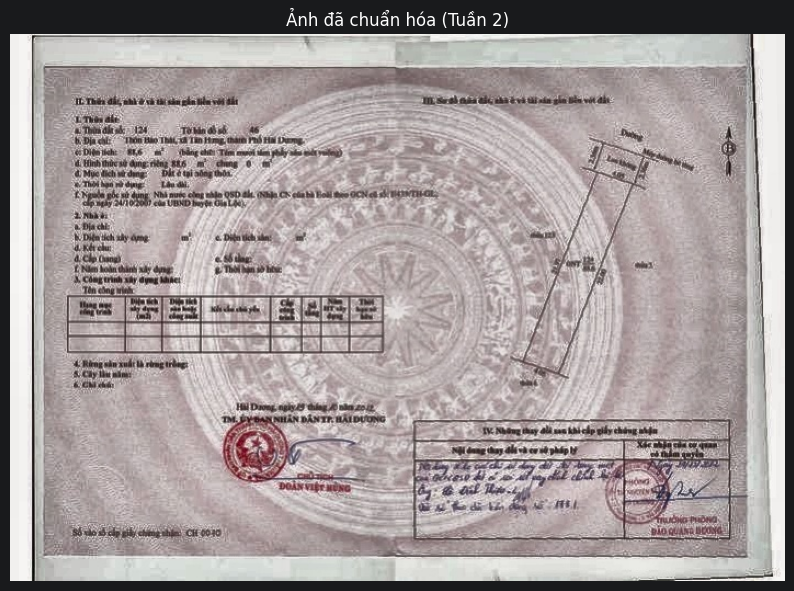

In [23]:
# ---- Nạp kết quả Tuần 2 ----
def _imread(name):
    img = cv2.imread(os.path.join(OUTPUT_DIR, name))
    assert img is not None, f"Không thấy {OUTPUT_DIR}/{name} — hãy chạy notebook Tuần 2 trước."
    return img

if all(k in globals() for k in ("enhanced", "flattened", "rois")):
    print("Dùng trực tiếp biến từ notebook Tuần 2 (enhanced, flattened, rois).")
else:
    print("Nạp từ thư mục outputs/ ...")
    flattened = _imread("04_flattened.jpg")
    enhanced = _imread("05_clahe_enhanced.jpg")
    van_ban = _imread("roi_van_ban.jpg")
    mask_text = (van_ban.max(axis=2) > 0).astype(np.uint8) * 255
    mask_text = cv2.morphologyEx(mask_text, cv2.MORPH_CLOSE, np.ones((25, 25), np.uint8))  # lấp lỗ chữ đen
    rois = {"van_ban": van_ban, "van_ban_mask": mask_text}
    for key, fn in (("con_dau", "roi_con_dau.jpg"), ("so_do", "roi_so_do.jpg")):
        p = os.path.join(OUTPUT_DIR, fn)
        if os.path.exists(p):
            rois[key] = cv2.imread(p)

print("ROI có sẵn:", [k for k in rois])
show(enhanced, "Ảnh đã chuẩn hóa (Tuần 2)")

## A. Phân tích nét vẽ sơ đồ thửa đất (Proposed Geometry Extraction)

1. Nhị phân hóa nét mực (adaptive threshold).
2. Tách **ký tự nhỏ** (chữ số kích thước cạnh) khỏi **nét vẽ dài** bằng connected components → nét vẽ không bị chữ số làm nhiễu.
3. **Skeletonization** → khung xương 1 px của đường ranh giới.
4. **HoughLinesP** trên khung xương → gộp các đoạn cộng tuyến → danh sách cạnh.
5. Giao điểm các cạnh (nằm sát đầu mút) → **tọa độ góc** thửa đất.

In [24]:
def binarize_ink(img, block=31, C=15):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv2.THRESH_BINARY_INV, block, C)


def split_glyphs_and_strokes(bw, glyph_ratio=0.04):
    """Thành phần liên thông nhỏ -> ký tự/chữ số; lớn -> nét vẽ."""
    n, lab, stats, _ = cv2.connectedComponentsWithStats(bw, connectivity=8)
    lim = glyph_ratio * max(bw.shape)
    is_glyph = np.zeros(n, bool)
    for i in range(1, n):
        if max(stats[i, cv2.CC_STAT_WIDTH], stats[i, cv2.CC_STAT_HEIGHT]) < lim:
            is_glyph[i] = True
    fg = lab > 0
    glyph = (is_glyph[lab] & fg).astype(np.uint8) * 255
    strokes = ((~is_glyph[lab]) & fg).astype(np.uint8) * 255
    return glyph, strokes


def skeletonize_strokes(strokes):
    strokes = cv2.morphologyEx(strokes, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
    return skeletonize(strokes > 0).astype(np.uint8) * 255


def hough_on_skeleton(skel, min_len_ratio=0.05, thr=30, gap=10):
    lines = cv2.HoughLinesP(skel, 1, np.pi / 180, thr,
                            minLineLength=int(min(skel.shape) * min_len_ratio), maxLineGap=gap)
    if lines is None:
        return []
    result = []
    for line in np.array(lines):
        flat_line = line.flatten()
        if len(flat_line) >= 4:
            result.append(tuple(map(float, flat_line[:4])))
    return result


def merge_segments(segs, ang_tol=5, dist_tol=8, gap_tol=25, min_len=30):
    """Gộp các đoạn cộng tuyến (cùng hướng, cùng đường, hở không quá gap_tol)."""
    segs = sorted(segs, key=lambda s: math.hypot(s[2] - s[0], s[3] - s[1]), reverse=True)
    cos_tol = math.cos(math.radians(ang_tol))
    clusters = []
    for x1, y1, x2, y2 in segs:
        p1, p2 = np.array([x1, y1]), np.array([x2, y2])
        v = p2 - p1
        L = np.linalg.norm(v)
        if L < 1e-6:
            continue
        for c in clusters:
            d, p0 = c["d"], c["p0"]
            n = np.array([-d[1], d[0]])
            if abs(np.dot(v, d)) / L < cos_tol:
                continue
            if max(abs(np.dot(p1 - p0, n)), abs(np.dot(p2 - p0, n))) > dist_tol:
                continue
            t1, t2 = np.dot(p1 - p0, d), np.dot(p2 - p0, d)
            lo, hi = min(t1, t2), max(t1, t2)
            if max(lo - c["hi"], c["lo"] - hi, 0) > gap_tol:
                continue
            c["lo"], c["hi"] = min(c["lo"], lo), max(c["hi"], hi)
            break
        else:
            clusters.append({"p0": p1, "d": v / L, "lo": 0.0, "hi": L})
    merged = []
    for c in clusters:
        a, b = c["p0"] + c["d"] * c["lo"], c["p0"] + c["d"] * c["hi"]
        length = float(np.linalg.norm(b - a))
        if length >= min_len:
            merged.append({"p1": a, "p2": b, "len": length})
    return sorted(merged, key=lambda s: -s["len"])


def line_intersection(a1, a2, b1, b2):
    d1, d2 = a2 - a1, b2 - b1
    den = d1[0] * d2[1] - d1[1] * d2[0]
    if abs(den) < 1e-6:
        return None
    t = ((b1[0] - a1[0]) * d2[1] - (b1[1] - a1[1]) * d2[0]) / den
    return a1 + t * d1


def point_seg_dist(p, a, b):
    ab = b - a
    t = np.clip(np.dot(p - a, ab) / (np.dot(ab, ab) + 1e-9), 0, 1)
    return float(np.linalg.norm(p - (a + t * ab)))


def find_corners(segs, snap=15, merge_dist=12, min_angle=25):
    pts = []
    for i in range(len(segs)):
        for j in range(i + 1, len(segs)):
            a, b = segs[i], segs[j]
            da, db = a["p2"] - a["p1"], b["p2"] - b["p1"]
            cosang = abs(np.dot(da, db)) / (np.linalg.norm(da) * np.linalg.norm(db) + 1e-9)
            if math.degrees(math.acos(min(1.0, cosang))) < min_angle:
                continue
            p = line_intersection(a["p1"], a["p2"], b["p1"], b["p2"])
            if p is None:
                continue
            if point_seg_dist(p, a["p1"], a["p2"]) <= snap and point_seg_dist(p, b["p1"], b["p2"]) <= snap:
                pts.append(p)
    corners = []
    for p in pts:
        for c in corners:
            if np.linalg.norm(c["p"] - p) < merge_dist:
                c["n"] += 1
                c["p"] = c["p"] + (p - c["p"]) / c["n"]
                break
        else:
            corners.append({"p": p.copy(), "n": 1})
    return [c["p"] for c in corners]

Hough: 45 đoạn thô -> 24 cạnh sau gộp, 7 góc


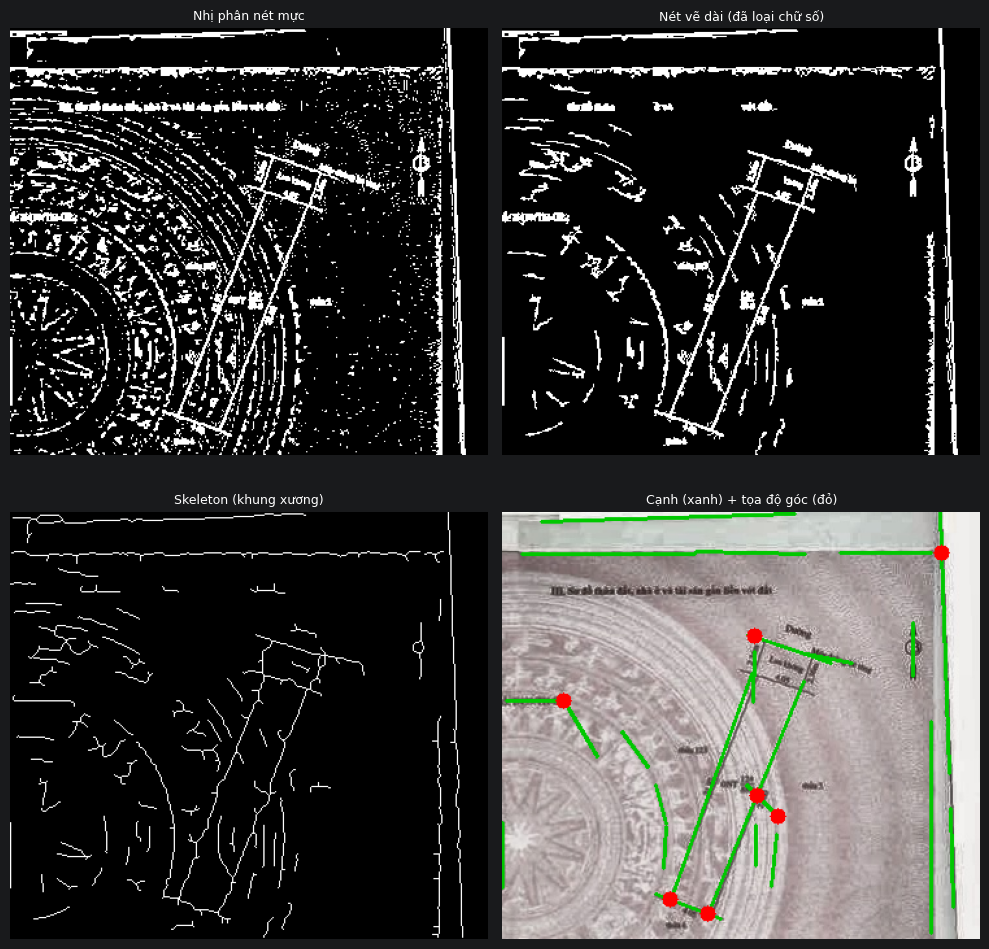

True

In [25]:
so_do = rois.get("so_do")
assert so_do is not None, "Chưa có ROI sơ đồ thửa đất từ Tuần 2."

bw_diagram = binarize_ink(so_do)
glyph_mask, stroke_mask = split_glyphs_and_strokes(bw_diagram)
skeleton = skeletonize_strokes(stroke_mask)

raw_segs = hough_on_skeleton(skeleton)
segs = merge_segments(raw_segs)
corners = find_corners(segs)
print(f"Hough: {len(raw_segs)} đoạn thô -> {len(segs)} cạnh sau gộp, {len(corners)} góc")

geo_vis = so_do.copy()
for s in segs:
    cv2.line(geo_vis, tuple(s["p1"].astype(int)), tuple(s["p2"].astype(int)), (0, 200, 0), 2)
for p in corners:
    cv2.circle(geo_vis, tuple(p.astype(int)), 6, (0, 0, 255), -1)

show_grid([
    (bw_diagram, "Nhị phân nét mực"),
    (stroke_mask, "Nét vẽ dài (đã loại chữ số)"),
    (skeleton, "Skeleton (khung xương)"),
    (geo_vis, "Cạnh (xanh) + tọa độ góc (đỏ)"),
], cols=2)
cv2.imwrite(os.path.join(OUTPUT_DIR, "07_skeleton.jpg"), skeleton)
cv2.imwrite(os.path.join(OUTPUT_DIR, "08_geometry.jpg"), geo_vis)

## B. Pipeline OCR đề xuất (Proposed OCR Pipeline)

1. Nhị phân hóa → xóa đường kẻ bảng (opening với kernel dài) → **Morphology Dilate** kernel ngang để gom ký tự thành dòng chữ.
2. Mỗi dòng cắt từ ảnh CLAHE → **VietOCR** (hoặc PaddleOCR) nhận dạng cả dòng.
3. Chuẩn hóa bỏ dấu (giữ nguyên độ dài chuỗi) → **regex chịu lỗi OCR** → 6 trường dữ liệu.

In [7]:
class Recognizer:
    """Bọc VietOCR / PaddleOCR thành 1 hàm: ảnh (BGR hoặc xám) -> chuỗi."""
    def __init__(self, engine="vietocr", device="cpu"):
        self.engine = engine
        if engine == "vietocr":
            from vietocr.tool.predictor import Predictor
            from vietocr.tool.config import Cfg
            cfg = Cfg.load_config_from_name("vgg_transformer")
            cfg["device"] = device
            cfg["cnn"]["pretrained"] = False
            cfg["predictor"]["beamsearch"] = False
            self.model = Predictor(cfg)
        elif engine == "paddle":
            from paddleocr import PaddleOCR
            try:    # PaddleOCR 3.x
                self.model = PaddleOCR(lang="vi", use_doc_orientation_classify=False,
                                       use_doc_unwarping=False, use_textline_orientation=False)
                self.v3 = True
            except Exception:   # PaddleOCR 2.x
                self.model = PaddleOCR(lang="vi", use_angle_cls=False, show_log=False)
                self.v3 = False
        else:
            raise ValueError(engine)

    def __call__(self, img):
        if img is None or img.size == 0:
            return ""
        if img.ndim == 2:
            img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
        if self.engine == "vietocr":
            from PIL import Image
            return self.model.predict(Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))).strip()
        if self.v3:
            res = self.model.predict(img)
            texts = [t for r in res for t in r.get("rec_texts", [])]
            return " ".join(texts).strip()
        res = self.model.ocr(img, det=True, cls=False)
        return " ".join(line[1][0] for line in (res[0] or [])).strip()


try:
    REC = Recognizer(CFG["OCR_ENGINE"], CFG["DEVICE"])
    print("OCR engine sẵn sàng:", CFG["OCR_ENGINE"])
except Exception as e:
    REC = None
    print("⚠ Chưa khởi tạo được OCR engine:", repr(e))
    print("  -> Cài vietocr/paddleocr (xem cell cài đặt). Các bước OCR sẽ bị bỏ qua.")

Model weight C:\Users\tcong\AppData\Local\Temp\vgg_transformer.pth exsits. Ignore download!
OCR engine sẵn sàng: vietocr


C:\Users\tcong\PycharmProjects\WelcomeScreen\.venv39\lib\site-packages\torch\nn\modules\transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(


In [5]:
TEXT_BOX = (0.0, 0.06, 0.52, 0.46)
# ----------------------------- 1. GOM DÒNG -----------------------------
def detect_text_lines(img_bgr, box=TEXT_BOX, kx=31, min_w=30, min_h=5, split_ratio=1.7, loc=0.4):
    """Trả về (boxes, gray, bw, dil). TỌA ĐỘ boxes TÍNH TRONG ẢNH CẮT `gray`, không phải toàn trang.
    img_bgr nên là ảnh phẳng hóa TRƯỚC CLAHE (Tuần 2: `flattened`)."""
    H, W = img_bgr.shape[:2]
    x0, y0, x1, y1 = int(box[0] * W), int(box[1] * H), int(box[2] * W), int(box[3] * H)
    gray = cv2.cvtColor(img_bgr[y0:y1, x0:x1], cv2.COLOR_BGR2GRAY)
 
    # Multi-Otsu 3 lớp: mực đen / hoa văn / giấy -> chỉ lấy ngưỡng thấp nhất = mực đen
    thr = threshold_multiotsu(gray, classes=3)[0]
    bw = ((gray < thr) * 255).astype(np.uint8)
 
    # Dilate NGANG: ký tự cùng dòng dính thành một khối
    dil = cv2.dilate(bw, cv2.getStructuringElement(cv2.MORPH_RECT, (kx, 1)))
    cnts, _ = cv2.findContours(dil, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxes = [b for b in map(cv2.boundingRect, cnts) if b[2] > min_w and b[3] >= min_h]
    if not boxes:
        return [], gray, bw, dil
 
    # Khối quá cao = nhiều dòng dính nhau -> tách bằng profile chiếu ngang.
    # Hàng được coi là "khe" khi tổng mực của nó < loc * (đỉnh lân cận): dòng ngắn/nhạt không bị coi là khe.
    med_h = float(np.median([b[3] for b in boxes]))
    out = []
    for (x, y, w, h) in boxes:
        if h < split_ratio * med_h:
            out.append((x, y, w, h))
            continue
        prof = np.convolve(bw[y:y + h, x:x + w].sum(axis=1) / 255.0, np.ones(3) / 3, mode="same")
        gap = (prof < loc * maximum_filter1d(prof, size=15)) | (prof < 1.0)
        start, found = None, []
        for i, g in enumerate(list(gap) + [True]):
            if not g and start is None:
                start = i
            if g and start is not None:
                if i - start >= 5:
                    xs = np.where(bw[y + start:y + i, x:x + w].sum(axis=0) > 0)[0]
                    found.append((int(x + xs.min()), int(y + start), int(xs.max() - xs.min() + 1), int(i - start)))
                start = None
        out.extend(found or [(x, y, w, h)])
 
    # Sắp xếp: theo hàng (trên -> dưới), trong hàng theo x (trái -> phải)
    out.sort(key=lambda b: b[1] + b[3] / 2)
    rows = [[out[0]]]
    for b in out[1:]:
        if abs((b[1] + b[3] / 2) - np.mean([r[1] + r[3] / 2 for r in rows[-1]])) < 0.6 * med_h:
            rows[-1].append(b)
        else:
            rows.append([b])
    ordered = [b for r in rows for b in sorted(r, key=lambda b: b[0])]
    return ordered, gray, bw, dil
 
 
# ----------------------------- 2. NHẬN DẠNG -----------------------------
def tesseract_line(img):
    return pytesseract.image_to_string(img, lang="vie", config="--psm 7").strip()
 
 
def recognize_lines(gray, boxes, rec=None, pad=3, upscale=3):
    """rec: hàm nhận ảnh xám của MỘT dòng -> chuỗi. Mặc định Tesseract tiếng Việt.
    Phóng to x3 trước khi OCR: chữ gốc chỉ cao ~10 px, quá nhỏ cho mọi bộ nhận dạng."""
    rec = rec or tesseract_line
    res = []
    for i, (x, y, w, h) in enumerate(boxes):
        crop = gray[max(0, y - pad):y + h + pad, max(0, x - pad):x + w + pad]
        crop = cv2.resize(crop, None, fx=upscale, fy=upscale, interpolation=cv2.INTER_CUBIC)
        res.append({"id": i, "box": (x, y, w, h), "text": rec(crop)})
    return res
 
 
# ----------------------------- 3. TRÍCH TRƯỜNG -----------------------------
def strip_accents(s):
    """Bỏ dấu, hạ chữ thường, GIỮ NGUYÊN độ dài chuỗi (để cắt giá trị từ chuỗi gốc theo vị trí khớp)."""
    s = unicodedata.normalize("NFC", s)
    return "".join("d" if ch in "đĐ" else unicodedata.normalize("NFD", ch)[0] for ch in s).lower()
 
 
ITEM_START = re.compile(r"^\W{0,3}(?:[a-zđ]\)|\d+\s*[\.\)])")   # "a)", "b)", "1.", "2)"...
 
FIELD_PATTERNS = {
    "so_thua":           r"thua\s*dat\D{0,6}?(?P<v>\d+)",
    "to_ban_do":         r"to\s*ban\s*do\D{0,6}?(?P<v>\d+)",
    "dien_tich":         r"dien\s*tich\s*[:.\-;]?\s*(?P<v>\d[\d.,;\s]*?)\s*m",
    "hinh_thuc_su_dung": r"hinh\s*thuc\s*\w+\s+\w+\W{0,3}(?P<v>.+?)(?=\s*muc\s*dich|\s*thoi\s*han|$)",
    "thoi_han_su_dung":  r"thoi\s*han\s*\w+\s+\w+\W{0,3}(?P<v>.+?)(?=\s*nguon\s*goc|\s*muc\s*dich|$)",
    "chu_so_huu":        r"\b(?:ong|ba)\b\s*[:.\-]?\s*(?P<v>[^\d;:]{3,})",
}
 
 
def lines_to_items(lines):
    """Dòng không mở đầu bằng 'a)', 'b)', '1.'... là phần tiếp của mục trước -> nối vào mục đó."""
    items = []
    for ln in lines:
        ln = ln.strip()
        if not ln:
            continue
        if not items or ITEM_START.match(strip_accents(ln)):
            items.append(ln)
        else:
            items[-1] += " " + ln
    return items
 
 
def extract_fields(lines_text):
    f = {}
    for key, pat in FIELD_PATTERNS.items():
        for item in lines_to_items(lines_text):
            m = re.search(pat, strip_accents(item))
            if not m:
                continue
            a, b = m.span("v")
            val = item[a:b].strip(" ;:,.-")
            if val:
                f[key] = re.sub(r"\s+", "", val).replace(";", ",") if key == "dien_tich" else val
                break
    return f

Phát hiện 19 dòng chữ


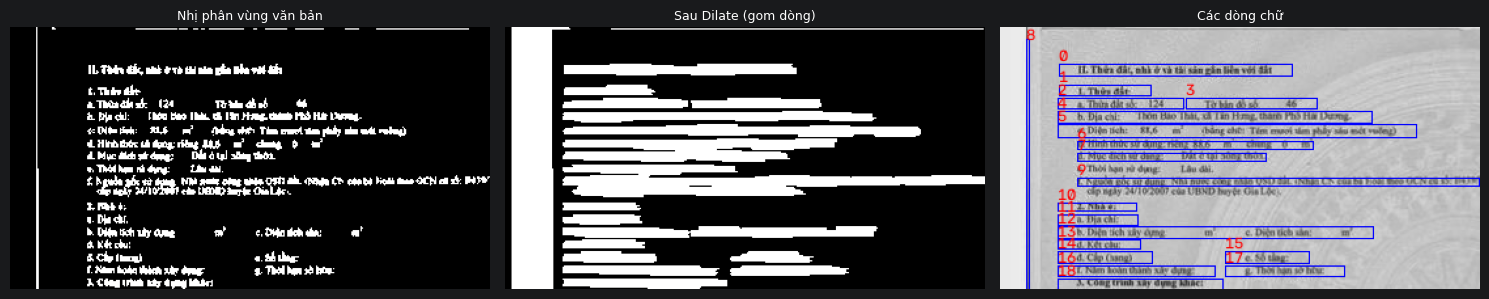

[00] 11. Thên đất, nhì ở và tài sản gần liên với sắt
[01] 1 Thứ cất
[02] Thừa đến sốc 124
[03] Tờ bản đồ số
[04] 6.Địa cái. Thôn Bảo Thai Ư Tên Hra Tham Phố Hà Dưng
[05] "Thị trong tiên tích: 81,6 - ? Diện (bằng chữ Tim mươi văm phẩy sâu ed vulep)"
[06] đ. Hình thức sử dung: nêng 886
[07] - Mục dích sứ đang - Đất ở tại nông thôa
[08] 1
[09] Thuận thế thức thế ( Ngườn gốc sử dụng Nhà nước công nhào OSD đất (Nhận CN của bà Hoài tạo OCN cã số: HOV Người Trường Thức
[10] 2 Nhà Ở
[11] Địa cài
[12] Diện ứch xây ông - Diện úch sân
[13] - Kết cầu
[14] Ở Cấp Gang
[15] - số thị
[16] Nên hoàn thành xây ông
[17] 2 Thời Năn sở hữu
[18] Công trình xây dựng khác

=== TRƯỜNG DỮ LIỆU TRÍCH XUẤT ===
so_thua             : — (không tìm thấy)
to_ban_do           : — (không tìm thấy)
dien_tich           : — (không tìm thấy)
hinh_thuc_su_dung   : nêng 886
thoi_han_su_dung    : — (không tìm thấy)
chu_so_huu          : Hoài tạo OCN cã số


True

In [8]:
# 1) Gom dòng: truyền ảnh phẳng TRƯỚC CLAHE; vùng chữ lấy theo TEXT_BOX (mặc định)
text_boxes, gray_txt, text_bw, text_dil = detect_text_lines(flattened)
print(f"Phát hiện {len(text_boxes)} dòng chữ")
 
# 2) Vẽ khung lên ảnh CẮT gray_txt (tọa độ boxes nằm trong ảnh cắt, không phải toàn trang)
line_vis = cv2.cvtColor(gray_txt, cv2.COLOR_GRAY2BGR)
for i, (x, y, w, h) in enumerate(text_boxes):
    cv2.rectangle(line_vis, (x, y), (x + w, y + h), (255, 0, 0), 1)
    cv2.putText(line_vis, str(i), (x, max(10, y - 2)), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 0, 255), 1)
show_grid([(text_bw, "Nhị phân vùng văn bản"), (text_dil, "Sau Dilate (gom dòng)"), (line_vis, "Các dòng chữ")], cols=3)
 
# 3) OCR: cắt từ gray_txt (CÙNG ảnh với boxes).
text_lines = recognize_lines(gray_txt, text_boxes, rec=REC)
for l in text_lines:
    print(f"[{l['id']:02d}] {l['text']}")
 
# 4) extract_fields mới trả về CHUỖI
fields = extract_fields([l["text"] for l in text_lines])
print("\n=== TRƯỜNG DỮ LIỆU TRÍCH XUẤT ===")
for k in FIELD_PATTERNS:
    print(f"{k:20s}: {fields.get(k, '— (không tìm thấy)')}")
cv2.imwrite(os.path.join(OUTPUT_DIR, "09_text_lines.jpg"), line_vis)

### B.2 Đọc nhãn kích thước trên sơ đồ & kiểm tra tính nhất quán nét vẽ

- Các **ký tự nhỏ** đã tách ở bước A được gom (dilate đẳng hướng) thành các nhãn số; mỗi nhãn được xoay về nằm ngang (PCA) rồi OCR (thử cả 2 chiều đọc).
- Gán mỗi nhãn cho cạnh gần nhất → tỉ lệ **px/m** của từng cạnh. Cạnh có tỉ lệ lệch bất thường so với median → nghi vấn bị sửa nét vẽ / sửa số.
- Diện tích đa giác (các góc kề cạnh có nhãn) / scale² được so với **diện tích OCR** từ văn bản.

In [9]:
NUM_RE = re.compile(r"\d{1,3}(?:[.,]\d{1,2})?")


def parse_dim(text):
    t = text.replace(" ", "").replace("m", "").replace("M", "")
    m = NUM_RE.fullmatch(t)
    return float(m.group(0).replace(",", ".")) if m else None


def find_label_blobs(glyph, k_ratio=0.012, min_area=40, max_side_ratio=0.25):
    k = max(7, int(k_ratio * max(glyph.shape)))
    dil = cv2.dilate(glyph, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    contours, _ = cv2.findContours(dil, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    blobs = []
    for c in contours:
        if cv2.contourArea(c) < min_area or len(c) < 5:
            continue
        (cx, cy), (w, h), _ = cv2.minAreaRect(c)
        if max(w, h) > max_side_ratio * max(glyph.shape):
            continue
        vx, vy, _, _ = cv2.fitLine(c, cv2.DIST_L2, 0, 0.01, 0.01).ravel()
        phi = math.degrees(math.atan2(vy, vx))
        if phi > 90: phi -= 180
        if phi <= -90: phi += 180
        blobs.append({"center": np.array([cx, cy]), "size": (max(w, h), min(w, h)), "angle": phi})
    return blobs


def crop_label(gray, blob, pad=6, flip=False):
    cx, cy = blob["center"]
    ang = blob["angle"] + (180 if flip else 0)
    M = cv2.getRotationMatrix2D((float(cx), float(cy)), ang, 1.0)
    rot = cv2.warpAffine(gray, M, (gray.shape[1], gray.shape[0]), flags=cv2.INTER_CUBIC,
                         borderMode=cv2.BORDER_REPLICATE)
    L, T = blob["size"]
    x0, x1 = int(cx - L / 2 - pad), int(cx + L / 2 + pad)
    y0, y1 = int(cy - T / 2 - pad), int(cy + T / 2 + pad)
    return rot[max(0, y0):y1, max(0, x0):x1]


def read_dimension_labels(gray, glyph, rec):
    labels = []
    for b in find_label_blobs(glyph):
        for flip in (False, True):           # thử cả 2 chiều đọc (0° và 180°)
            txt = rec(crop_label(gray, b, flip=flip))
            val = parse_dim(txt)
            if val is not None:
                labels.append({"center": b["center"], "text": txt, "value": val})
                break
    return labels


def assign_labels_to_edges(segs, labels, max_dist_ratio=0.06, shape=None):
    max_d = max_dist_ratio * max(shape)
    for s in segs:
        s.pop("label", None)
    for lb in labels:
        d = [point_seg_dist(lb["center"], s["p1"], s["p2"]) for s in segs]
        if not d:
            continue
        j = int(np.argmin(d))
        if d[j] <= max_d and ("label" not in segs[j] or d[j] < segs[j]["label_dist"]):
            segs[j]["label"], segs[j]["label_dist"] = lb["value"], d[j]
    return segs


def polygon_area(pts):
    pts = np.array(pts)
    c = pts.mean(axis=0)
    pts = pts[np.argsort(np.arctan2(pts[:, 1] - c[1], pts[:, 0] - c[0]))]
    x, y = pts[:, 0], pts[:, 1]
    return 0.5 * abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))


def check_geometry_consistency(segs, corners, ocr_area=None, scale_tol=0.15, area_tol=0.10, snap=15):
    res = {"n_labeled": 0, "px_per_m": None, "edges": [], "area_diagram_m2": None,
           "area_ocr_m2": ocr_area, "flags": []}
    labeled = [s for s in segs if "label" in s]
    res["n_labeled"] = len(labeled)
    if len(labeled) < 2:
        res["flags"].append("INFO: <2 cạnh có nhãn kích thước -> không kiểm tra được tỉ lệ")
        return res
    ratios = np.array([s["len"] / s["label"] for s in labeled])
    med = float(np.median(ratios))
    res["px_per_m"] = med
    for s, r in zip(labeled, ratios):
        dev = abs(r / med - 1)
        res["edges"].append({"p1": s["p1"].tolist(), "p2": s["p2"].tolist(), "len_px": s["len"],
                             "label_m": s["label"], "px_per_m": float(r), "deviation": float(dev),
                             "suspicious": bool(dev > scale_tol)})
        if dev > scale_tol:
            res["flags"].append(f"CẠNH NGHI VẤN: nhãn {s['label']} m, lệch tỉ lệ {dev:.0%}")
    # diện tích đa giác từ các góc kề cạnh có nhãn
    pts = [c for c in corners if any(point_seg_dist(c, s["p1"], s["p2"]) <= snap for s in labeled)]
    if len(pts) >= 3:
        a = polygon_area(pts) / med ** 2
        res["area_diagram_m2"] = float(a)
        if ocr_area:
            dev = abs(a / ocr_area - 1)
            res["area_dev"] = float(dev)
            if dev > area_tol:
                res["flags"].append(f"DIỆN TÍCH LỆCH: sơ đồ ≈ {a:.1f} m² vs văn bản {ocr_area} m² ({dev:.0%})")
    return res

Nhãn kích thước đọc được: [('1', 1.0), ('1', 1.0), ('1', 1.0), ('3', 3.0), ('1', 1.0), ('35', 35.0), ('1', 1.0), ('6', 6.0), ('1', 1.0), ('127', 127.0), ('01', 1.0), ('1', 1.0), ('5', 5.0), ('1', 1.0), ('03', 3.0), ('01', 1.0), ('1', 1.0), ('1', 1.0), ('8', 8.0), ('1', 1.0), ('50', 50.0), ('1', 1.0), ('5', 5.0), ('1', 1.0), ('1', 1.0), ('1', 1.0), ('1', 1.0), ('20', 20.0), ('1', 1.0), ('4', 4.0), ('1', 1.0), ('1', 1.0), ('1', 1.0), ('7', 7.0), ('1', 1.0), ('1', 1.0), ('1', 1.0), ('1', 1.0), ('15', 15.0), ('1', 1.0), ('1', 1.0), ('0', 0.0), ('1', 1.0), ('19', 19.0), ('1', 1.0), ('19', 19.0), ('1', 1.0), ('19', 19.0), ('4', 4.0), ('1', 1.0)]
Tỉ lệ px/m (median): 67.00000168622687
Diện tích sơ đồ: 3.7235665266250813 m² | Diện tích OCR: None m²
 - CẠNH NGHI VẤN: nhãn 1.0 m, lệch tỉ lệ 190%
 - CẠNH NGHI VẤN: nhãn 1.0 m, lệch tỉ lệ 190%
 - CẠNH NGHI VẤN: nhãn 1.0 m, lệch tỉ lệ 178%
 - CẠNH NGHI VẤN: nhãn 1.0 m, lệch tỉ lệ 99%
 - CẠNH NGHI VẤN: nhãn 1.0 m, lệch tỉ lệ 67%
 - CẠNH NGHI VẤN: nhã

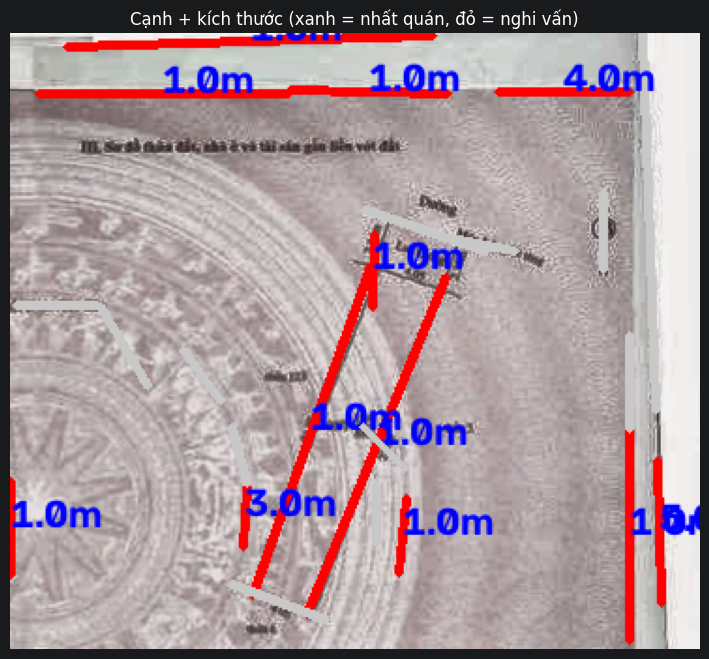

True

In [10]:
geo_gray = cv2.cvtColor(so_do, cv2.COLOR_BGR2GRAY)
dim_labels = read_dimension_labels(geo_gray, glyph_mask, REC) if REC else []
segs = assign_labels_to_edges(segs, dim_labels, shape=so_do.shape[:2])

def get_ocr_area(fields):
    v = fields.get("dien_tich") if isinstance(fields, dict) else None
    if isinstance(v, dict):         
        v = v.get("value")
    if isinstance(v, str):
        m = re.search(r"\d[\d.,\s]*", v)
        v = parse_area(m.group(0)) if m else None
    return v

ocr_area = get_ocr_area(fields)    

geo_check = check_geometry_consistency(segs, corners, ocr_area,
                                       scale_tol=CFG["SCALE_TOL"], area_tol=CFG["AREA_TOL"])

print(f"Nhãn kích thước đọc được: {[(l['text'], l['value']) for l in dim_labels]}")
print(f"Tỉ lệ px/m (median): {geo_check['px_per_m']}")
print(f"Diện tích sơ đồ: {geo_check['area_diagram_m2']} m² | Diện tích OCR: {geo_check['area_ocr_m2']} m²")
for f in geo_check["flags"]:
    print(" -", f)

geo_vis2 = so_do.copy()
for s in segs:
    bad = any(e["suspicious"] and np.allclose(e["p1"], s["p1"]) for e in geo_check["edges"])
    col = (0, 0, 255) if bad else ((0, 200, 0) if "label" in s else (200, 200, 200))
    cv2.line(geo_vis2, tuple(s["p1"].astype(int)), tuple(s["p2"].astype(int)), col, 3)
    if "label" in s:
        m = ((s["p1"] + s["p2"]) / 2).astype(int)
        cv2.putText(geo_vis2, f"{s['label']}m", tuple(m), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2)
show(geo_vis2, "Cạnh + kích thước (xanh = nhất quán, đỏ = nghi vấn)")
cv2.imwrite(os.path.join(OUTPUT_DIR, "10_geometry_check.jpg"), geo_vis2)

## C. Đánh giá trùng khớp con dấu bằng LBP

1. Chuẩn hóa con dấu: lấy bản đồ "độ đỏ" (R − max(G,B)) → cắt sát mực dấu → vuông 128×128.
2. **LBP rotation-invariant uniform** ở 2 tỉ lệ (P=8,R=1) và (P=16,R=2); histogram chia **lưới 4×4** để giữ thông tin không gian.
3. So với mẫu chuẩn bằng **histogram intersection** ∈ [0, 1]; quét xoay 0–345° (bước 15°) vì dấu có thể đóng nghiêng. Lấy điểm cao nhất; nhiều mẫu chuẩn → lấy max.

Đặt các ảnh mẫu chuẩn vào `data/stamp_templates/*.jpg` (cắt từ giấy tờ hợp lệ, cùng cơ quan cấp).

In [11]:
STAMP_SIZE = 128
LBP_SETTINGS = [(8, 1), (16, 2)]
GRID = 4


def normalize_stamp(img_bgr, size=STAMP_SIZE):
    b, g, r = [img_bgr[:, :, i].astype(np.int16) for i in range(3)]
    redness = np.clip(r - np.maximum(g, b), 0, 255).astype(np.uint8)
    redness = cv2.normalize(redness, None, 0, 255, cv2.NORM_MINMAX)
    _, m = cv2.threshold(redness, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    ys, xs = np.nonzero(m)
    if len(xs) < 50:                       # không thấy mực đỏ -> dùng ảnh xám đảo
        gray = 255 - cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
        crop = gray
    else:
        crop = redness[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = crop.shape
    s = max(h, w)
    canvas = np.zeros((s, s), np.uint8)
    canvas[(s - h) // 2:(s - h) // 2 + h, (s - w) // 2:(s - w) // 2 + w] = crop
    return cv2.resize(canvas, (size, size), interpolation=cv2.INTER_AREA)


def lbp_grid_hist(gray, P, R, grid=GRID):
    lbp = local_binary_pattern(gray, P, R, method="uniform")      # rotation-invariant uniform
    bins = P + 2
    H, W = gray.shape
    hists = []
    for gy in range(grid):
        for gx in range(grid):
            cell = lbp[gy * H // grid:(gy + 1) * H // grid, gx * W // grid:(gx + 1) * W // grid]
            h, _ = np.histogram(cell, bins=bins, range=(0, bins))
            hists.append(h / (h.sum() + 1e-9))
    return np.array(hists)


def stamp_features(gray):
    return [lbp_grid_hist(gray, P, R) for P, R in LBP_SETTINGS]


def hist_intersection(f1, f2):
    return float(np.mean([np.minimum(a, b).sum(axis=1).mean() for a, b in zip(f1, f2)]))


def rotate_gray(gray, ang):
    h, w = gray.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), ang, 1.0)
    return cv2.warpAffine(gray, M, (w, h), flags=cv2.INTER_LINEAR, borderValue=0)


def stamp_similarity(query_gray, template_feats, angles=range(0, 360, 15)):
    best, best_ang = -1.0, 0
    for ang in angles:
        s = max(hist_intersection(stamp_features(rotate_gray(query_gray, ang)), tf) for tf in template_feats)
        if s > best:
            best, best_ang = s, ang
    return best, best_ang


def calibrate_threshold(genuine_scores, fake_scores):
    """Chọn ngưỡng tối đa độ chính xác từ điểm của con dấu thật / giả (dùng khi đã có dữ liệu thử)."""
    cands = np.unique(np.concatenate([genuine_scores, fake_scores]))
    accs = [(np.mean(np.array(genuine_scores) >= t) + np.mean(np.array(fake_scores) < t)) / 2 for t in cands]
    return float(cands[int(np.argmax(accs))]), float(max(accs))

⚠ Chưa có mẫu con dấu chuẩn tại data/stamp_templates/*.jpg
Điểm LBP = 1.000 (góc xoay tốt nhất 0°), ngưỡng 0.75 -> KHỚP | DEMO (chưa có mẫu chuẩn — tự so với chính nó, điểm vô nghĩa)


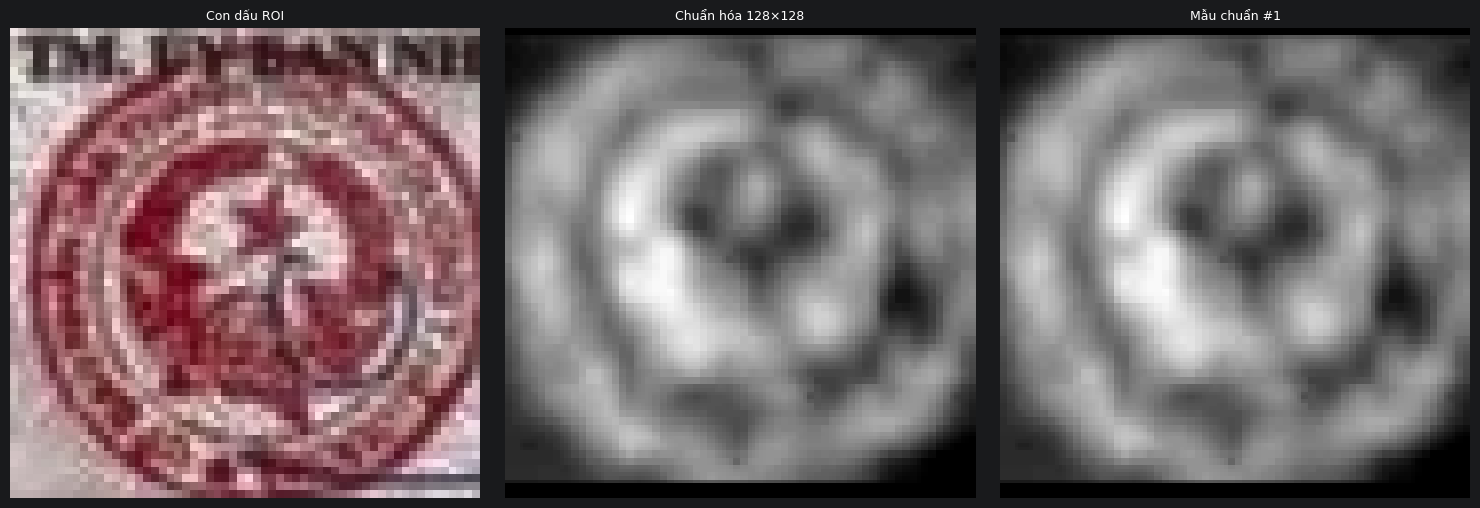

In [12]:
stamp_result = {"score": None, "angle": None, "match": None, "mode": None}
stamp_roi = rois.get("con_dau")

if stamp_roi is None:
    print("⚠ Không có ROI con dấu từ Tuần 2.")
else:
    q = normalize_stamp(stamp_roi)
    tpl_paths = sorted(glob.glob(CFG["STAMP_TEMPLATE_GLOB"]))
    if tpl_paths:
        tpl_imgs = [normalize_stamp(cv2.imread(p)) for p in tpl_paths]
        stamp_result["mode"] = f"so với {len(tpl_paths)} mẫu chuẩn"
    else:
        tpl_imgs = [q]
        stamp_result["mode"] = "DEMO (chưa có mẫu chuẩn — tự so với chính nó, điểm vô nghĩa)"
        print("⚠ Chưa có mẫu con dấu chuẩn tại", CFG["STAMP_TEMPLATE_GLOB"])
    tpl_feats = [stamp_features(t) for t in tpl_imgs]
    score, ang = stamp_similarity(q, tpl_feats)
    stamp_result.update(score=score, angle=ang, match=bool(score >= CFG["STAMP_THR"]))
    print(f"Điểm LBP = {score:.3f} (góc xoay tốt nhất {ang}°), ngưỡng {CFG['STAMP_THR']} -> "
          f"{'KHỚP' if stamp_result['match'] else 'KHÔNG KHỚP'} | {stamp_result['mode']}")
    show_grid([(stamp_roi, "Con dấu ROI"), (q, "Chuẩn hóa 128×128"), (tpl_imgs[0], "Mẫu chuẩn #1")], cols=3)

## D. Hợp nhất: phát hiện can thiệp + báo cáo cuối

In [13]:
REQUIRED = ["so_thua", "to_ban_do", "dien_tich", "hinh_thuc_su_dung", "thoi_han_su_dung", "chu_so_huu"]


def build_report():
    flags = []
    # 1. Con dấu
    if stamp_result["score"] is None:
        flags.append(("INFO", "Không kiểm tra được con dấu"))
    elif not stamp_result["match"]:
        flags.append(("CAO", f"Con dấu không khớp mẫu chuẩn (LBP={stamp_result['score']:.2f} < {CFG['STAMP_THR']})"))
    # 2. Nét vẽ / kích thước sơ đồ
    for f in geo_check["flags"]:
        flags.append(("INFO" if f.startswith("INFO") else "CAO", f))
    # 3. Trường dữ liệu OCR
    missing = [k for k in REQUIRED if k not in fields]
    if missing:
        flags.append(("TRUNG BÌNH", f"OCR thiếu trường: {', '.join(missing)}"))
    high = [f for f in flags if f[0] == "CAO"]
    verdict = "NGHI VẤN CAN THIỆP" if high else "KHÔNG PHÁT HIỆN BẤT THƯỜNG"
    return {
        "verdict": verdict,
        "fields": {k: (fields.get(k).get("value") if isinstance(fields.get(k), dict) else fields.get(k))
           for k in REQUIRED},
        "diagram": {
            "n_edges": len(segs), "n_corners": len(corners),
            "corners_px": [c.tolist() for c in corners],
            "px_per_m": geo_check["px_per_m"],
            "edges_labeled": geo_check["edges"],
            "area_diagram_m2": geo_check["area_diagram_m2"],
        },
        "stamp": stamp_result,
        "flags": [{"level": l, "msg": m} for l, m in flags],
    }


report = build_report()
with open(os.path.join(OUTPUT_DIR, "report_tuan4.json"), "w", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=2,
              default=lambda o: o.item() if hasattr(o, "item") else (o.tolist() if hasattr(o, "tolist") else str(o)))

print("=" * 60)
print("KẾT LUẬN:", report["verdict"])
print("=" * 60)
for k, v in report["fields"].items():
    print(f"  {k:20s}: {v}")
print(f"  Sơ đồ: {report['diagram']['n_edges']} cạnh, {report['diagram']['n_corners']} góc, "
      f"px/m={report['diagram']['px_per_m']}")
print(f"  Con dấu: score={report['stamp']['score']} match={report['stamp']['match']}")
for fl in report["flags"]:
    print(f"  [{fl['level']}] {fl['msg']}")

KẾT LUẬN: NGHI VẤN CAN THIỆP
  so_thua             : None
  to_ban_do           : None
  dien_tich           : None
  hinh_thuc_su_dung   : nêng 886
  thoi_han_su_dung    : None
  chu_so_huu          : Hoài tạo OCN cã số
  Sơ đồ: 24 cạnh, 7 góc, px/m=67.00000168622687
  Con dấu: score=0.9999999999990234 match=True
  [CAO] CẠNH NGHI VẤN: nhãn 1.0 m, lệch tỉ lệ 190%
  [CAO] CẠNH NGHI VẤN: nhãn 1.0 m, lệch tỉ lệ 190%
  [CAO] CẠNH NGHI VẤN: nhãn 1.0 m, lệch tỉ lệ 178%
  [CAO] CẠNH NGHI VẤN: nhãn 1.0 m, lệch tỉ lệ 99%
  [CAO] CẠNH NGHI VẤN: nhãn 1.0 m, lệch tỉ lệ 67%
  [CAO] CẠNH NGHI VẤN: nhãn 1.0 m, lệch tỉ lệ 25%
  [CAO] CẠNH NGHI VẤN: nhãn 5.0 m, lệch tỉ lệ 77%
  [CAO] CẠNH NGHI VẤN: nhãn 4.0 m, lệch tỉ lệ 74%
  [CAO] CẠNH NGHI VẤN: nhãn 1.0 m, lệch tỉ lệ 25%
  [CAO] CẠNH NGHI VẤN: nhãn 1.0 m, lệch tỉ lệ 40%
  [CAO] CẠNH NGHI VẤN: nhãn 1.0 m, lệch tỉ lệ 42%
  [CAO] CẠNH NGHI VẤN: nhãn 3.0 m, lệch tỉ lệ 84%
  [TRUNG BÌNH] OCR thiếu trường: so_thua, to_ban_do, dien_tich, thoi_han_su_dung


## Ghi chú cho báo cáo

- **Tham số cần hiệu chỉnh trên dữ liệu thật:** `STAMP_THR`, `SCALE_TOL`, `AREA_TOL`, `kx_ratio` (gom dòng), `thr/minLineLength` (Hough).
- **Giới hạn đã biết:** (1) kiểm tra tỉ lệ px/m chỉ có nghĩa khi sơ đồ vẽ đúng tỉ lệ; (2) diện tích đa giác phụ thuộc việc các góc kề cạnh có nhãn thuộc đúng thửa; (3) con dấu đè lên sơ đồ/chữ sẽ làm nhiễu nhánh A và B; (4) regex trường dữ liệu theo mẫu GCN phổ biến — mẫu khác cần chỉnh `FIELD_PATTERNS`.
- **Tuần 5 (đánh giá):** tạo tập ảnh thật/giả (sửa số, thay con dấu, vẽ lại cạnh), chạy `report_tuan4.json` hàng loạt, tính Precision/Recall/F1 và CER/WER cho OCR; dùng `calibrate_threshold` để chọn ngưỡng con dấu.